In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

In [7]:
df= pd.read_csv(
    r"C:\10k\da_project\Sample - Superstore.csv",
    encoding="latin1"
)
print(df.head())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [9]:
# First five records
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [11]:
# Last five records
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2017-119914,5/4/2017,5/9/2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


In [6]:
# Random five records
df.sample(5)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
1652,1653,US-2017-132444,11/18/2017,11/21/2017,First Class,CD-12280,Christina DeMoss,Consumer,United States,Seattle,Washington,98105,West,OFF-ST-10003442,Office Supplies,Storage,Eldon Portable Mobile Manager,169.68,6,0.00,45.81
2256,2257,CA-2016-164091,9/17/2016,9/22/2016,Standard Class,LA-16780,Laura Armstrong,Corporate,United States,Bangor,Maine,4401,East,FUR-FU-10004952,Furniture,Furnishings,C-Line Cubicle Keepers Polyproplyene Holder w/...,109.48,2,0.00,33.94
7972,7973,US-2015-126753,8/16/2015,8/20/2015,Standard Class,SP-20860,Sung Pak,Corporate,United States,Philadelphia,Pennsylvania,19134,East,OFF-PA-10002787,Office Supplies,Paper,Xerox 227,10.37,2,0.20,3.63
5379,5380,CA-2016-136021,8/14/2016,8/18/2016,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Los Angeles,California,90045,West,OFF-PA-10000551,Office Supplies,Paper,Array Memo Cubes,15.54,3,0.00,7.61
6038,6039,CA-2016-131205,9/4/2016,9/8/2016,Standard Class,AA-10645,Anna Andreadi,Consumer,United States,Georgetown,Kentucky,40324,South,OFF-ST-10002583,Office Supplies,Storage,Fellowes Neat Ideas Storage Cubes,129.92,4,0.00,5.20


In [21]:
# Number of rows and columns
df.shape


(9994, 21)

In [8]:
# Column names
df.columns


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [9]:
# Number of records
len(df)


9994

In [10]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [11]:
# Statistical summary of numerical columns
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"4,997.50","55,190.38",229.86,3.79,0.16,28.66
std,"2,885.16","32,063.69",623.25,2.23,0.21,234.26
min,1.00,"1,040.00",0.44,1.00,0.00,"-6,599.98"
25%,"2,499.25","23,223.00",17.28,2.00,0.00,1.73
50%,"4,997.50","56,430.50",54.49,3.00,0.20,8.67
75%,"7,495.75","90,008.00",209.94,5.00,0.20,29.36
max,"9,994.00","99,301.00","22,638.48",14.00,0.80,"8,399.98"


In [12]:
# Summary of categorical columns
df.describe(include="object")

C:\Users\tejom\AppData\Local\Temp\ipykernel_9628\292326849.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994
unique,5009,1237,1334,4,793,793,3,1,531,49,4,1862,3,17,1850
top,CA-2017-100111,9/5/2016,12/16/2015,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,38,35,5968,37,37,5191,9994,915,2001,3203,19,6026,1523,48


In [13]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [14]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

categorical_columns = df.select_dtypes(
    include="object"
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit']

Categorical Columns:
['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']


C:\Users\tejom\AppData\Local\Temp\ipykernel_9628\2837707706.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [15]:
df.nunique()

Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64

In [16]:
print("Unique Customers:", df["Customer ID"].nunique())

print("Unique Products:", df["Product ID"].nunique())

print("Unique Orders:", df["Order ID"].nunique())

Unique Customers: 793
Unique Products: 1862
Unique Orders: 5009


In [17]:
print("Categories:", df["Category"].unique())

print("Subcategories:", df["Sub-Category"].unique())

print("Regions:", df["Region"].unique())

print("Segments:", df["Segment"].unique())

print("Shipping Modes:", df["Ship Mode"].unique())

Categories: <StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str
Subcategories: <StringArray>
[  'Bookcases',      'Chairs',      'Labels',      'Tables',     'Storage',
 'Furnishings',         'Art',      'Phones',     'Binders',  'Appliances',
       'Paper', 'Accessories',   'Envelopes',   'Fasteners',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str
Regions: <StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str
Segments: <StringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str
Shipping Modes: <StringArray>
['Second Class', 'Standard Class', 'First Class', 'Same Day']
Length: 4, dtype: str


In [18]:
# Check missing values
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [19]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df)
    ) * 100
})

missing_report

,Missing_Count,Missing_Percentage
Row ID,0,0.00
Order ID,0,0.00
Order Date,0,0.00
Ship Date,0,0.00
Ship Mode,0,0.00
Customer ID,0,0.00
Customer Name,0,0.00
Segment,0,0.00
Country,0,0.00
City,0,0.00


In [20]:
df[df.isnull().any(axis=1)]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


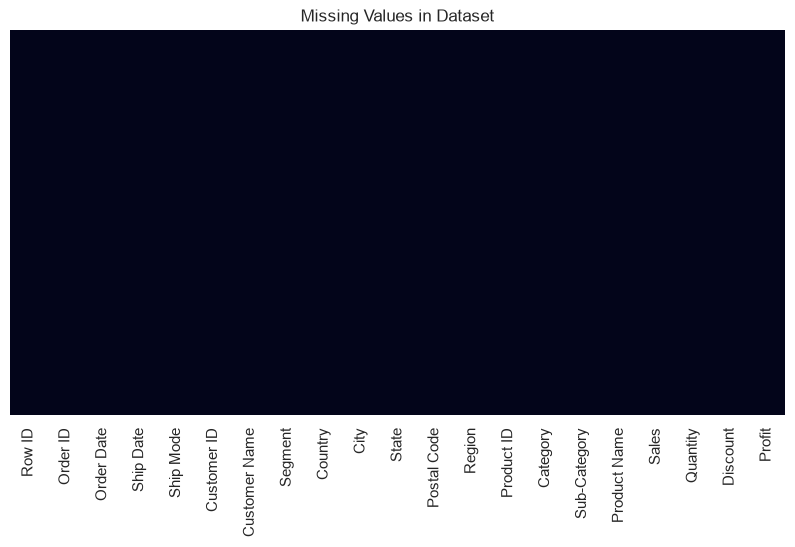

In [21]:
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Dataset")
plt.show()

In [22]:
# Count exact duplicate rows
df.duplicated().sum()

np.int64(0)

In [23]:
# Display exact duplicate records
df[df.duplicated()]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [24]:
df["Order ID"].duplicated().sum()

np.int64(4985)

In [25]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [26]:
df[["Order Date", "Ship Date"]].head(10)

,Order Date,Ship Date
0,11/8/2016,11/11/2016
1,11/8/2016,11/11/2016
2,6/12/2016,6/16/2016
3,10/11/2015,10/18/2015
4,10/11/2015,10/18/2015
5,6/9/2014,6/14/2014
6,6/9/2014,6/14/2014
7,6/9/2014,6/14/2014
8,6/9/2014,6/14/2014
9,6/9/2014,6/14/2014


In [27]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"4,997.50","55,190.38",229.86,3.79,0.16,28.66
std,"2,885.16","32,063.69",623.25,2.23,0.21,234.26
min,1.00,"1,040.00",0.44,1.00,0.00,"-6,599.98"
25%,"2,499.25","23,223.00",17.28,2.00,0.00,1.73
50%,"4,997.50","56,430.50",54.49,3.00,0.20,8.67
75%,"7,495.75","90,008.00",209.94,5.00,0.20,29.36
max,"9,994.00","99,301.00","22,638.48",14.00,0.80,"8,399.98"


In [28]:
df[df["Sales"] < 0]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [29]:
df[df["Quantity"] < 0]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [30]:
df[df["Profit"] < 0]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
14,15,US-2015-118983,11/22/2015,11/26/2015,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106,Central,OFF-AP-10002311,Office Supplies,Appliances,Holmes Replacement Filter for HEPA Air Cleaner...,68.81,5,0.80,-123.86
15,16,US-2015-118983,11/22/2015,11/26/2015,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106,Central,OFF-BI-10000756,Office Supplies,Binders,Storex DuraTech Recycled Plastic Frosted Binders,2.54,3,0.80,-3.82
23,24,US-2017-156909,7/16/2017,7/18/2017,Second Class,SF-20065,Sandra Flanagan,Consumer,United States,Philadelphia,Pennsylvania,19140,East,FUR-CH-10002774,Furniture,Chairs,"Global Deluxe Stacking Chair, Gray",71.37,2,0.30,-1.02
27,28,US-2015-150630,9/17/2015,9/21/2015,Standard Class,TB-21520,Tracy Blumstein,Consumer,United States,Philadelphia,Pennsylvania,19140,East,FUR-BO-10004834,Furniture,Bookcases,"Riverside Palais Royal Lawyers Bookcase, Royal...","3,083.43",7,0.50,"-1,665.05"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9920,9921,CA-2016-149272,3/15/2016,3/19/2016,Standard Class,MY-18295,Muhammed Yedwab,Corporate,United States,Bryan,Texas,77803,Central,OFF-BI-10004233,Office Supplies,Binders,"GBC Pre-Punched Binding Paper, Plastic, White,...",22.39,7,0.80,-35.82
9921,9922,CA-2014-111360,11/24/2014,11/30/2014,Standard Class,AT-10435,Alyssa Tate,Home Office,United States,Akron,Ohio,44312,East,OFF-BI-10003350,Office Supplies,Binders,Acco Expandable Hanging Binders,5.74,3,0.70,-4.59
9931,9932,CA-2015-104948,11/13/2015,11/17/2015,Standard Class,KH-16510,Keith Herrera,Consumer,United States,San Bernardino,California,92404,West,FUR-BO-10004357,Furniture,Bookcases,O'Sullivan Living Dimensions 3-Shelf Bookcases,683.33,4,0.15,-40.20
9937,9938,CA-2016-164889,6/3/2016,6/6/2016,Second Class,CP-12340,Christine Phan,Corporate,United States,Los Angeles,California,90049,West,FUR-TA-10001676,Furniture,Tables,Hon 61000 Series Interactive Training Tables,71.09,2,0.20,-1.78


In [31]:
df["Discount"].describe()

count   9,994.00
mean        0.16
std         0.21
min         0.00
25%         0.00
50%         0.20
75%         0.20
max         0.80
Name: Discount, dtype: float64

In [32]:
order_dates = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

ship_dates = pd.to_datetime(
    df["Ship Date"],
    errors="coerce"
)

In [33]:
print("Invalid Order Dates:", order_dates.isna().sum())

print("Invalid Ship Dates:", ship_dates.isna().sum())

Invalid Order Dates: 0
Invalid Ship Dates: 0


In [34]:
df.loc[
    ship_dates < order_dates,
    ["Order ID", "Order Date", "Ship Date"]
]

,Order ID,Order Date,Ship Date


In [35]:
df_clean = df.copy()

In [36]:
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    errors="coerce"
)

In [37]:
df_clean.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [38]:
df_clean.duplicated().sum()

np.int64(0)

In [39]:
df_clean = df_clean.drop_duplicates()

In [40]:
df_clean.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [41]:
text_columns = df_clean.select_dtypes(
    include="object"
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

C:\Users\tejom\AppData\Local\Temp\ipykernel_9628\575074160.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(


In [42]:
df_clean["Category"].value_counts(dropna=False)

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

In [43]:
# Negative sales
negative_sales = df_clean[df_clean["Sales"] < 0]

# Negative quantity
negative_quantity = df_clean[df_clean["Quantity"] < 0]

# Negative profit
negative_profit = df_clean[df_clean["Profit"] < 0]

In [44]:
print("Original Shape:", df.shape)

print("Cleaned Shape:", df_clean.shape)

Original Shape: (9994, 21)
Cleaned Shape: (9994, 21)


In [45]:
print("Missing Values:")
print(df_clean.isnull().sum())

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [46]:
print("Exact Duplicates:", df_clean.duplicated().sum())

Exact Duplicates: 0


In [47]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [48]:
total_sales = df_clean["Sales"].sum()

print("Total Sales:", total_sales)

Total Sales: 2297200.8603


In [49]:
total_profit = df_clean["Profit"].sum()

print("Total Profit:", total_profit)

Total Profit: 286397.0217


In [50]:
total_quantity = df_clean["Quantity"].sum()

print("Total Quantity:", total_quantity)

Total Quantity: 37873


In [51]:
total_orders = df_clean["Order ID"].nunique()

print("Total Orders:", total_orders)

Total Orders: 5009


In [52]:
total_customers = df_clean["Customer ID"].nunique()

print("Total Customers:", total_customers)

Total Customers: 793


In [53]:
profit_margin = (
    total_profit / total_sales
) * 100 if total_sales != 0 else np.nan

print("Profit Margin:", profit_margin)

Profit Margin: 12.467217240315605


In [54]:
kpi_report = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Quantity",
        "Total Orders",
        "Total Customers",
        "Profit Margin (%)"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_quantity,
        total_orders,
        total_customers,
        profit_margin
    ]
})

kpi_report

,Metric,Value
0,Total Sales,"2,297,200.86"
1,Total Profit,"286,397.02"
2,Total Quantity,"37,873.00"
3,Total Orders,"5,009.00"
4,Total Customers,793.00
5,Profit Margin (%),12.47


In [55]:
category_sales = (
    df_clean.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

Category
Technology        836,154.03
Furniture         741,999.80
Office Supplies   719,047.03
Name: Sales, dtype: float64

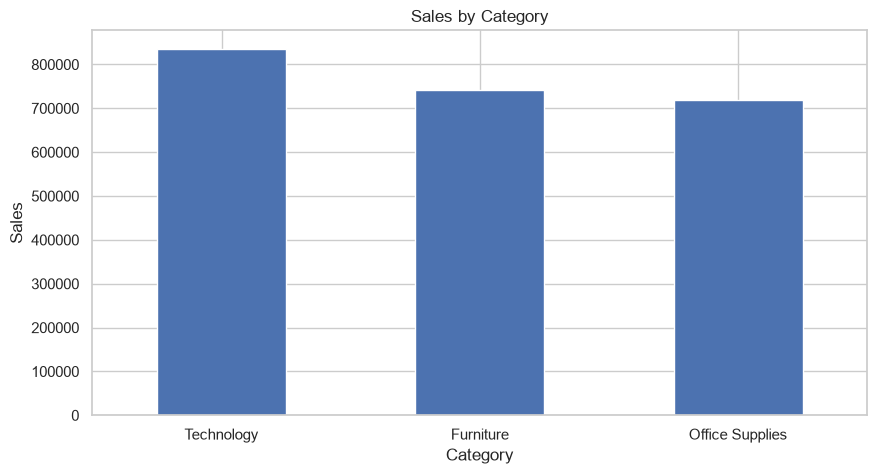

In [56]:
category_sales.plot(
    kind="bar",
    title="Sales by Category",
    xlabel="Category",
    ylabel="Sales"
)

plt.xticks(rotation=0)
plt.show()

In [57]:
category_profit = (
    df_clean.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

Category
Technology        145,454.95
Office Supplies   122,490.80
Furniture          18,451.27
Name: Profit, dtype: float64

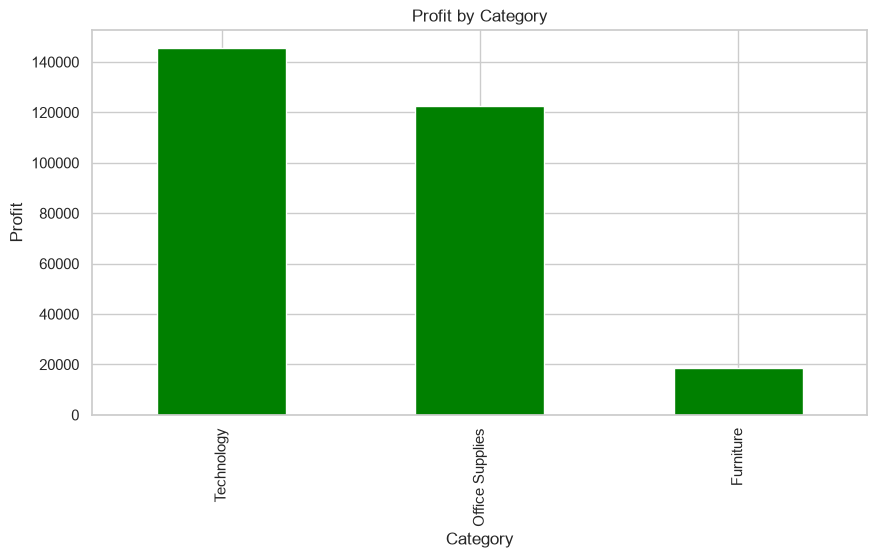

In [58]:
category_profit.plot(
    kind="bar",
    title="Profit by Category",
    color="green"
)

plt.ylabel("Profit")
plt.show()

In [59]:
subcategory_analysis = (
    df_clean.groupby("Sub-Category")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Quantity": "sum"
    })
    .sort_values("Sales", ascending=False)
)

subcategory_analysis

,Sales,Profit,Quantity
Sub-Category,,,
Phones,"330,007.05","44,515.73",3289
Chairs,"328,449.10","26,590.17",2356
Storage,"223,843.61","21,278.83",3158
Tables,"206,965.53","-17,725.48",1241
Binders,"203,412.73","30,221.76",5974
Machines,"189,238.63","3,384.76",440
Accessories,"167,380.32","41,936.64",2976
Copiers,"149,528.03","55,617.82",234
Bookcases,"114,880.00","-3,472.56",868


In [60]:
subcategory_analysis.head(5)

,Sales,Profit,Quantity
Sub-Category,,,
Phones,"330,007.05","44,515.73",3289
Chairs,"328,449.10","26,590.17",2356
Storage,"223,843.61","21,278.83",3158
Tables,"206,965.53","-17,725.48",1241
Binders,"203,412.73","30,221.76",5974


In [61]:
subcategory_analysis.sort_values(
    "Profit"
).head(5)

,Sales,Profit,Quantity
Sub-Category,,,
Tables,"206,965.53","-17,725.48",1241
Bookcases,"114,880.00","-3,472.56",868
Supplies,"46,673.54","-1,189.10",647
Fasteners,"3,024.28",949.52,914
Machines,"189,238.63","3,384.76",440


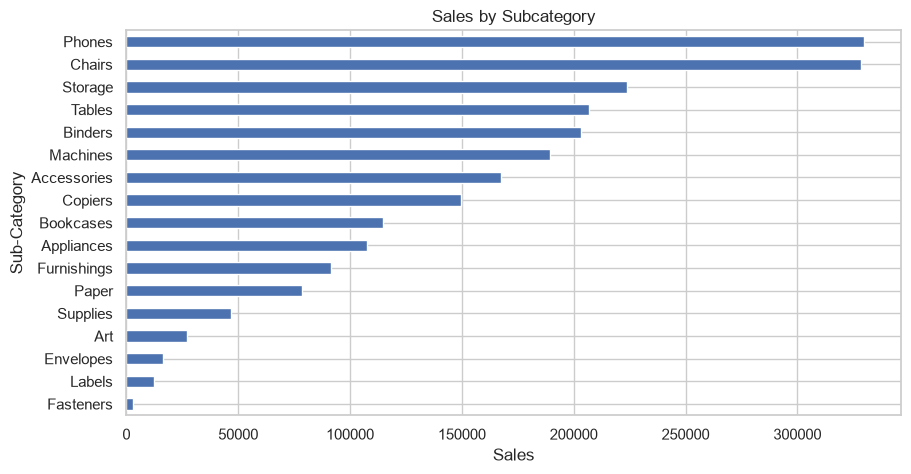

In [62]:
subcategory_analysis["Sales"].sort_values().plot(
    kind="barh",
    title="Sales by Subcategory"
)

plt.xlabel("Sales")
plt.show()

In [63]:
region_analysis = (
    df_clean.groupby("Region")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Quantity": "sum",
        "Order ID": "nunique"
    })
    .rename(columns={
        "Order ID": "Total Orders"
    })
)

region_analysis

,Sales,Profit,Quantity,Total Orders
Region,,,,
Central,"501,239.89","39,706.36",8780,1175
East,"678,781.24","91,522.78",10618,1401
South,"391,721.91","46,749.43",6209,822
West,"725,457.82","108,418.45",12266,1611


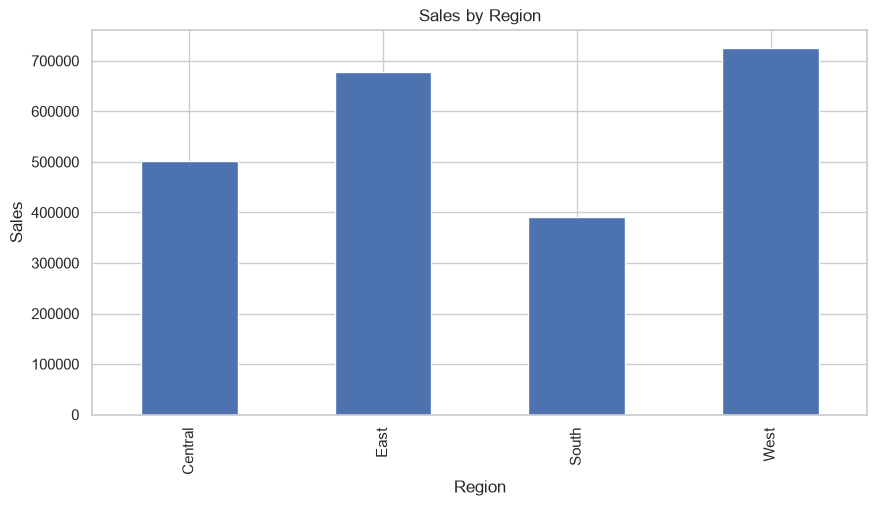

In [64]:
region_analysis["Sales"].plot(
    kind="bar",
    title="Sales by Region"
)

plt.ylabel("Sales")
plt.show()

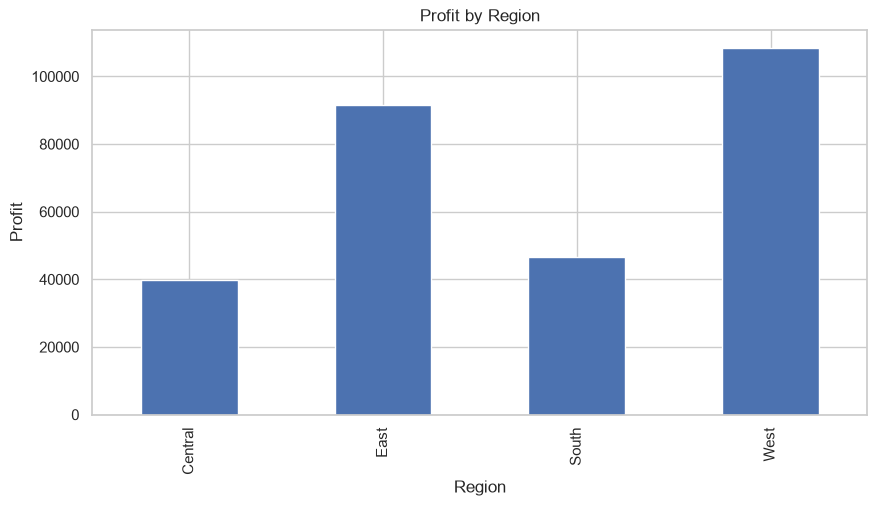

In [65]:
region_analysis["Profit"].plot(
    kind="bar",
    title="Profit by Region"
)

plt.ylabel("Profit")
plt.show()

In [66]:
segment_analysis = (
    df_clean.groupby("Segment")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Customer ID": "nunique",
        "Order ID": "nunique"
    })
    .rename(columns={
        "Customer ID": "Customers",
        "Order ID": "Orders"
    })
)

segment_analysis

,Sales,Profit,Customers,Orders
Segment,,,,
Consumer,"1,161,401.34","134,119.21",409,2586
Corporate,"706,146.37","91,979.13",236,1514
Home Office,"429,653.15","60,298.68",148,909


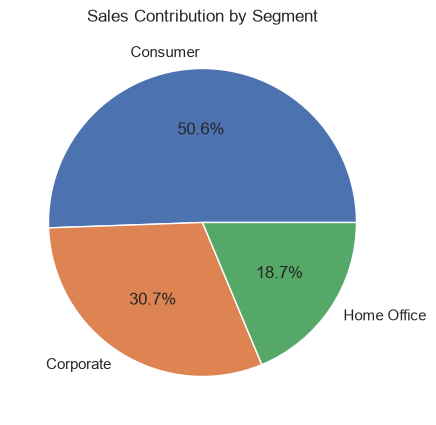

In [67]:
segment_analysis["Sales"].plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Sales Contribution by Segment"
)

plt.ylabel("")
plt.show()

In [68]:
df_clean["Year"] = df_clean["Order Date"].dt.year

df_clean["Month"] = df_clean["Order Date"].dt.month

df_clean["Month_Name"] = (
    df_clean["Order Date"].dt.month_name()
)

In [69]:
monthly_sales = (
    df_clean.groupby(
        df_clean["Order Date"].dt.to_period("M")
    )["Sales"]
    .sum()
)

monthly_sales

Order Date
2014-01    14,236.90
2014-02     4,519.89
2014-03    55,691.01
2014-04    28,295.35
2014-05    23,648.29
2014-06    34,595.13
2014-07    33,946.39
2014-08    27,909.47
2014-09    81,777.35
2014-10    31,453.39
2014-11    78,628.72
2014-12    69,545.62
2015-01    18,174.08
2015-02    11,951.41
2015-03    38,726.25
2015-04    34,195.21
2015-05    30,131.69
2015-06    24,797.29
2015-07    28,765.33
2015-08    36,898.33
2015-09    64,595.92
2015-10    31,404.92
2015-11    75,972.56
2015-12    74,919.52
2016-01    18,542.49
2016-02    22,978.81
2016-03    51,715.88
2016-04    38,750.04
2016-05    56,987.73
2016-06    40,344.53
2016-07    39,261.96
2016-08    31,115.37
2016-09    73,410.02
2016-10    59,687.75
2016-11    79,411.97
2016-12    96,999.04
2017-01    43,971.37
2017-02    20,301.13
2017-03    58,872.35
2017-04    36,521.54
2017-05    44,261.11
2017-06    52,981.73
2017-07    45,264.42
2017-08    63,120.89
2017-09    87,866.65
2017-10    77,776.92
2017-11   118,447.82
20

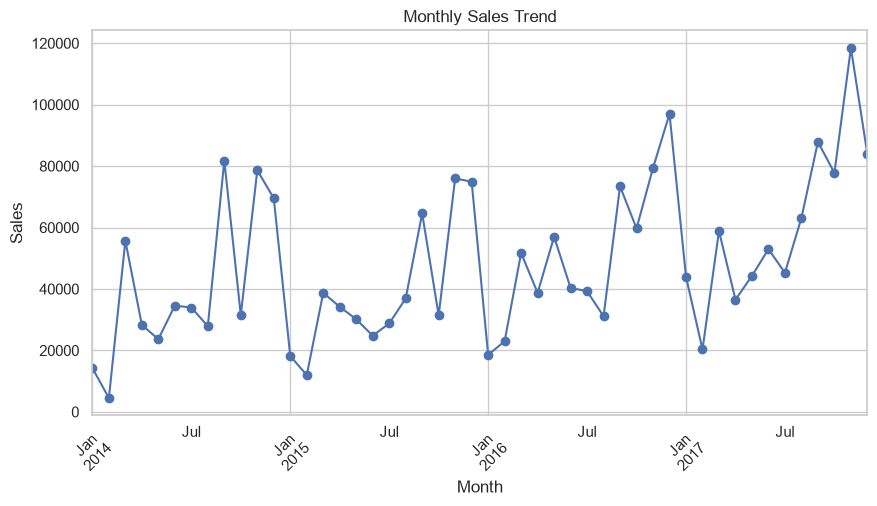

In [70]:
monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

In [71]:
yearly_sales = (
    df_clean.groupby("Year")["Sales"]
    .sum()
)

yearly_sales

Year
2014   484,247.50
2015   470,532.51
2016   609,205.60
2017   733,215.26
Name: Sales, dtype: float64

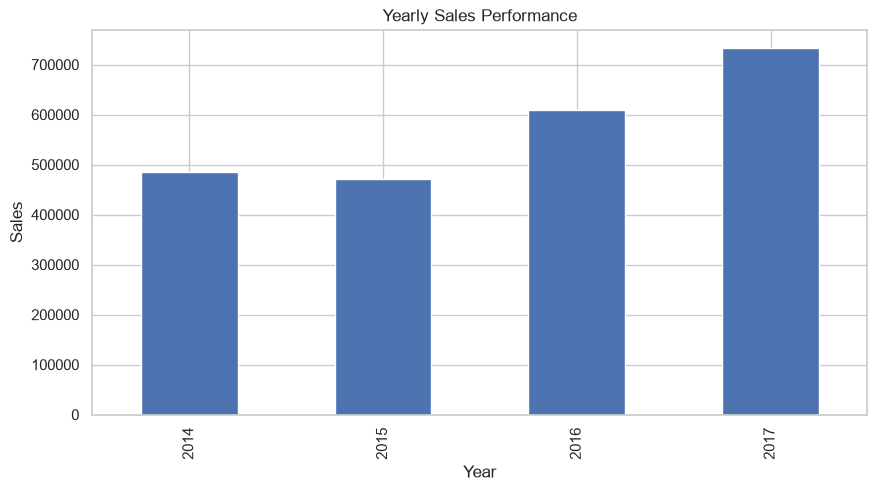

In [72]:
yearly_sales.plot(
    kind="bar",
    title="Yearly Sales Performance"
)

plt.ylabel("Sales")
plt.show()

In [73]:
top_customers = (
    df_clean.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer Name
Sean Miller          25,043.05
Tamara Chand         19,052.22
Raymond Buch         15,117.34
Tom Ashbrook         14,595.62
Adrian Barton        14,473.57
Ken Lonsdale         14,175.23
Sanjit Chand         14,142.33
Hunter Lopez         12,873.30
Sanjit Engle         12,209.44
Christopher Conant   12,129.07
Name: Sales, dtype: float64

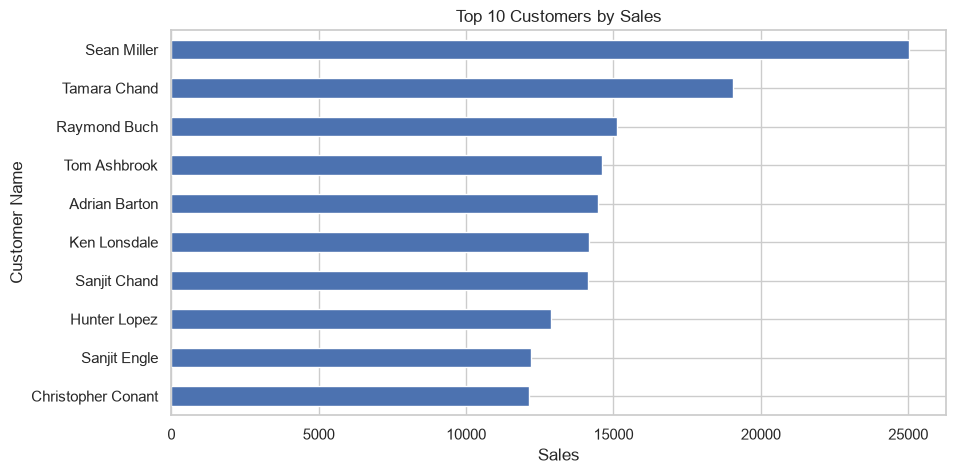

In [74]:
top_customers.sort_values().plot(
    kind="barh",
    title="Top 10 Customers by Sales"
)

plt.xlabel("Sales")
plt.show()

In [75]:
top_products = (
    df_clean.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                         61,599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind   27,453.38
Cisco TelePresence System EX90 Videoconferencing Unit                         22,638.48
HON 5400 Series Task Chairs for Big and Tall                                  21,870.58
GBC DocuBind TL300 Electric Binding System                                    19,823.48
GBC Ibimaster 500 Manual ProClick Binding System                              19,024.50
Hewlett Packard LaserJet 3310 Copier                                          18,839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                     18,374.90
GBC DocuBind P400 Electric Binding System                                     17,965.07
High Speed Automatic Electric Letter Opener                                   17,030.31
Name: Sales, dtype: float64

In [76]:
top_products = (
    df_clean.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                         61,599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind   27,453.38
Cisco TelePresence System EX90 Videoconferencing Unit                         22,638.48
HON 5400 Series Task Chairs for Big and Tall                                  21,870.58
GBC DocuBind TL300 Electric Binding System                                    19,823.48
GBC Ibimaster 500 Manual ProClick Binding System                              19,024.50
Hewlett Packard LaserJet 3310 Copier                                          18,839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                     18,374.90
GBC DocuBind P400 Electric Binding System                                     17,965.07
High Speed Automatic Electric Letter Opener                                   17,030.31
Name: Sales, dtype: float64

In [77]:
top_products = (
    df_clean.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                         61,599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind   27,453.38
Cisco TelePresence System EX90 Videoconferencing Unit                         22,638.48
HON 5400 Series Task Chairs for Big and Tall                                  21,870.58
GBC DocuBind TL300 Electric Binding System                                    19,823.48
GBC Ibimaster 500 Manual ProClick Binding System                              19,024.50
Hewlett Packard LaserJet 3310 Copier                                          18,839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                     18,374.90
GBC DocuBind P400 Electric Binding System                                     17,965.07
High Speed Automatic Electric Letter Opener                                   17,030.31
Name: Sales, dtype: float64

In [78]:
discount_profit_corr = df_clean[
    ["Discount", "Profit"]
].corr()

discount_profit_corr

,Discount,Profit
Discount,1.00,-0.22
Profit,-0.22,1.00


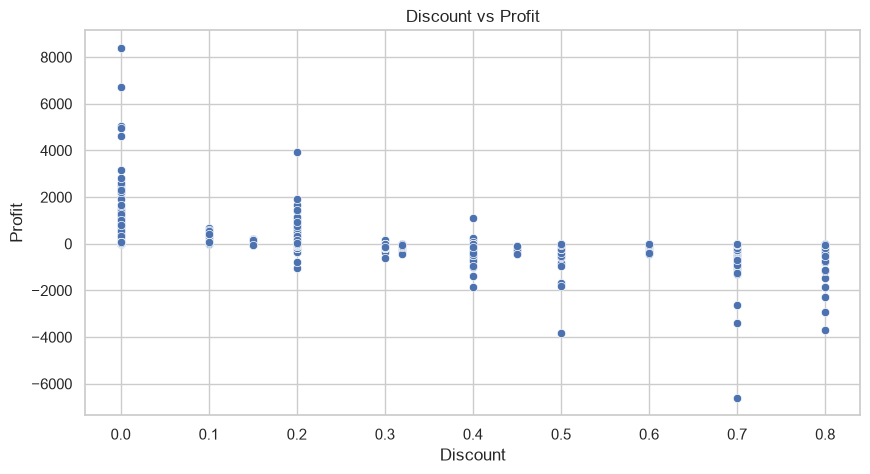

In [79]:
sns.scatterplot(
    data=df_clean,
    x="Discount",
    y="Profit"
)

plt.title("Discount vs Profit")
plt.show()

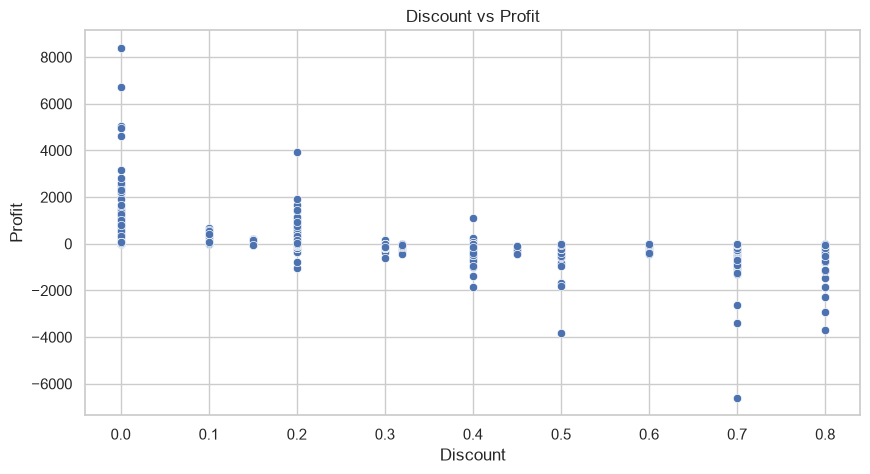

In [80]:
sns.scatterplot(
    data=df_clean,
    x="Discount",
    y="Profit"
)

plt.title("Discount vs Profit")
plt.show()

In [81]:
discount_analysis = (
    df_clean.groupby("Discount")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Order ID": "nunique"
    })
)

discount_analysis

,Sales,Profit,Order ID
Discount,,,
0.00,"1,087,908.47","320,987.60",2644
0.10,"54,369.35","9,029.18",89
0.15,"27,558.52","1,418.99",51
0.20,"764,594.37","90,337.31",2407
0.30,"103,226.65","-10,369.28",211
0.32,"14,493.46","-2,391.14",27
0.40,"116,417.78","-23,057.05",185
0.45,"5,484.97","-2,493.11",10
0.50,"58,918.54","-20,506.43",64


In [82]:
df_clean["Shipping Days"] = (
    df_clean["Ship Date"] -
    df_clean["Order Date"]
).dt.days

In [83]:
shipping_analysis = (
    df_clean.groupby("Ship Mode")
    .agg({
        "Shipping Days": "mean",
        "Order ID": "nunique",
        "Sales": "sum"
    })
    .rename(columns={
        "Order ID": "Total Orders",
        "Shipping Days": "Average Shipping Days"
    })
)

shipping_analysis

,Average Shipping Days,Total Orders,Sales
Ship Mode,,,
First Class,2.18,787,"351,428.42"
Same Day,0.04,264,"128,363.12"
Second Class,3.24,964,"459,193.57"
Standard Class,5.01,2994,"1,358,215.74"


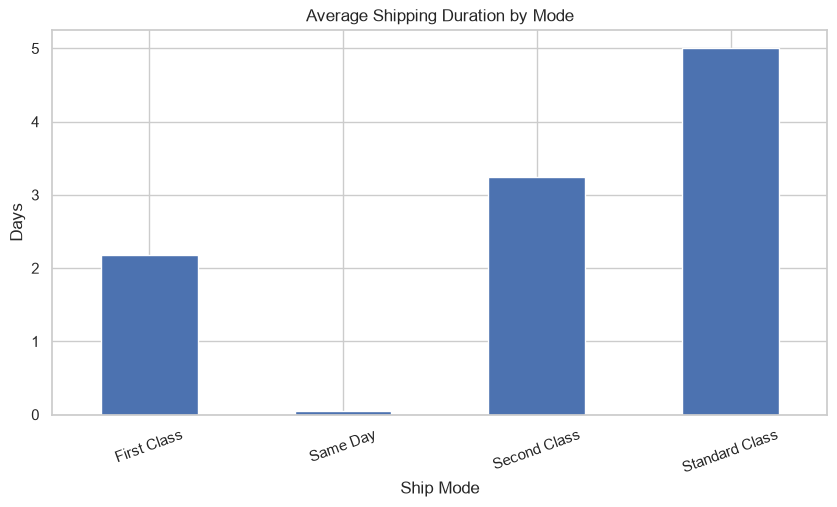

In [84]:
shipping_analysis["Average Shipping Days"].plot(
    kind="bar",
    title="Average Shipping Duration by Mode"
)

plt.ylabel("Days")
plt.xticks(rotation=20)
plt.show()

In [85]:
os.makedirs("../processed_data", exist_ok=True)

df_clean.to_csv(
    "../processed_data/cleaned_superstore.csv",
    index=False
)

In [90]:
os.makedirs("../reports", exist_ok=True)

category_analysis = (
    df_clean.groupby("Category")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Quantity": "sum"
    })
)
category_analysis

# category_analysis.to_csv(
#     "../reports/category_analysis.csv"
# )

,Sales,Profit,Quantity
Category,,,
Furniture,"741,999.80","18,451.27",8028
Office Supplies,"719,047.03","122,490.80",22906
Technology,"836,154.03","145,454.95",6939


In [87]:
region_analysis.to_csv(
    "../reports/region_analysis.csv"
)

In [88]:
segment_analysis.to_csv(
    "../reports/segment_analysis.csv"
)

In [89]:
kpi_report.to_csv(
    "../reports/kpi_report.csv",
    index=False
)